In [92]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

movies = pd.read_csv("movies.csv")
print(movies.shape)
genre_groups = pd.read_csv("genre_groups.csv")
print(genre_groups.shape)

(3201, 16)
(12, 2)


# Testing dataset first

In [93]:
movies.head()
movies.info()

<class 'pandas.DataFrame'>
RangeIndex: 3201 entries, 0 to 3200
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Title                   3200 non-null   str    
 1   US Gross                3194 non-null   float64
 2   Worldwide Gross         3194 non-null   float64
 3   US DVD Sales            564 non-null    float64
 4   Production Budget       3200 non-null   float64
 5   Release Date            3201 non-null   str    
 6   MPAA Rating             2596 non-null   str    
 7   Running Time min        1209 non-null   float64
 8   Distributor             2969 non-null   str    
 9   Source                  2836 non-null   str    
 10  Major Genre             2926 non-null   str    
 11  Creative Type           2755 non-null   str    
 12  Director                1870 non-null   str    
 13  Rotten Tomatoes Rating  2321 non-null   float64
 14  IMDB Rating             2988 non-null   float64
 15

In [94]:
movies.head()

,Title,US Gross,Worldwide Gross,US DVD Sales,Production Budget,Release Date,MPAA Rating,Running Time min,Distributor,Source,Major Genre,Creative Type,Director,Rotten Tomatoes Rating,IMDB Rating,IMDB Votes
0,The Land Girls,146083.0,146083.0,NaN,8000000.0,Jun 12 1998,R,NaN,Gramercy,NaN,NaN,NaN,NaN,NaN,6.1,1071.0
1,"First Love, Last Rites",10876.0,10876.0,NaN,300000.0,Aug 07 1998,R,NaN,Strand,NaN,Drama,NaN,NaN,NaN,6.9,207.0
2,I Married a Strange Person,203134.0,203134.0,NaN,250000.0,Aug 28 1998,NaN,NaN,Lionsgate,NaN,Comedy,NaN,NaN,NaN,6.8,865.0
3,Let's Talk About Sex,373615.0,373615.0,NaN,300000.0,Sep 11 1998,NaN,NaN,Fine Line,NaN,Comedy,NaN,NaN,13.0,NaN,NaN
4,Slam,1009819.0,1087521.0,NaN,1000000.0,Oct 09 1998,R,NaN,Trimark,Original Screenplay,Drama,Contemporary Fiction,NaN,62.0,3.4,165.0


In [95]:
genre_groups.head()

,Major Genre,Genre group
0,Drama,Drama
1,Comedy,Comedy & music
2,Romantic Comedy,Comedy & music
3,Black Comedy,Comedy & music
4,Musical,Comedy & music


In [96]:
genre_groups.info()

<class 'pandas.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Major Genre  12 non-null     str  
 1   Genre group  12 non-null     str  
dtypes: str(2)
memory usage: 324.0 bytes


In [97]:
movies[["US Gross", "Worldwide Gross"]].count()

US Gross           3194
Worldwide Gross    3194
dtype: int64

In [98]:
view = ["Title","US Gross", "Worldwide Gross", "Production Budget", "IMDB Rating", "Rotten Tomatoes Rating"]
movies[view].head()

,Title,US Gross,Worldwide Gross,Production Budget,IMDB Rating,Rotten Tomatoes Rating
0,The Land Girls,146083.0,146083.0,8000000.0,6.1,NaN
1,"First Love, Last Rites",10876.0,10876.0,300000.0,6.9,NaN
2,I Married a Strange Person,203134.0,203134.0,250000.0,6.8,NaN
3,Let's Talk About Sex,373615.0,373615.0,300000.0,NaN,13.0
4,Slam,1009819.0,1087521.0,1000000.0,3.4,62.0


In [99]:
movies["Major Genre"].describe()

count      2926
unique       12
top       Drama
freq        789
Name: Major Genre, dtype: object

In [100]:
movies["US Gross"].describe()

count    3.194000e+03
mean     4.400209e+07
std      6.255531e+07
min      0.000000e+00
25%      5.493221e+06
50%      2.201947e+07
75%      5.609176e+07
max      7.601676e+08
Name: US Gross, dtype: float64

In [101]:
print(movies["Production Budget"].head(3))

0    8000000.0
1     300000.0
2     250000.0
Name: Production Budget, dtype: float64


In [102]:
print(movies["Production Budget"].dtype)

float64


# More testing...

In [103]:
movies[["Title", "Production Budget"]].sort_values(by="Production Budget", ascending=False).head(10)

,Title,Production Budget
2508,Pirates of the Caribbean: At World's End,300000000.0
2824,Spider-Man 3,258000000.0
1974,Harry Potter and the Half-Blood Prince,250000000.0
1234,Avatar,237000000.0
2828,Superman Returns,232000000.0
2065,Quantum of Solace,230000000.0
2507,Pirates of the Caribbean: Dead Man's Chest,225000000.0
2397,The Chronicles of Narnia: Prince Caspian,225000000.0
2600,Robin Hood,210000000.0
2941,Transformers: Revenge of the Fallen,210000000.0


In [104]:
mask = ((movies["Major Genre"] == "Action") & (movies["Production Budget"] > 100000000))
movies.loc[mask]

,Title,US Gross,Worldwide Gross,US DVD Sales,Production Budget,Release Date,MPAA Rating,Running Time min,Distributor,Source,Major Genre,Creative Type,Director,Rotten Tomatoes Rating,IMDB Rating,IMDB Votes
1041,Waterworld,88246220.0,2.642462e+08,NaN,175000000.0,Jul 28 1995,PG-13,NaN,Universal,Original Screenplay,Action,Science Fiction,Kevin Reynolds,42.0,5.7,54126.0
1074,2012,166112167.0,7.668122e+08,50736023.0,200000000.0,Nov 13 2009,PG-13,158.0,Sony Pictures,Original Screenplay,Action,Science Fiction,Roland Emmerich,39.0,6.2,396.0
1218,The A-Team,77222099.0,1.760479e+08,NaN,110000000.0,Jun 11 2010,PG-13,119.0,20th Century Fox,Based on TV,Action,NaN,Joe Carnahan,47.0,7.2,29886.0
1234,Avatar,760167650.0,2.767891e+09,146153933.0,237000000.0,Dec 18 2009,PG-13,NaN,20th Century Fox,Original Screenplay,Action,Science Fiction,James Cameron,83.0,8.3,261439.0
1249,Bad Boys II,138540870.0,2.729409e+08,NaN,130000000.0,Jul 18 2003,R,147.0,Sony Pictures,Original Screenplay,Action,Contemporary Fiction,Michael Bay,24.0,6.2,58002.0
1264,Batman Begins,205343774.0,3.723530e+08,NaN,150000000.0,Jun 15 2005,PG-13,140.0,Warner Bros.,Based on Comic/Graphic Novel,Action,Super Hero,Christopher Nolan,84.0,8.3,270641.0
1266,The Dark Knight,533345358.0,1.022345e+09,234119058.0,185000000.0,Jul 18 2008,PG-13,152.0,Warner Bros.,Based on Comic/Graphic Novel,Action,Super Hero,Christopher Nolan,93.0,8.9,465000.0
1355,The Bourne Ultimatum,227471070.0,4.421616e+08,123314592.0,130000000.0,Aug 03 2007,PG-13,114.0,Universal,Based on Book/Short Story,Action,Contemporary Fiction,Paul Greengrass,93.0,8.2,146025.0
1395,Batman & Robin,107325195.0,2.383178e+08,NaN,125000000.0,Jun 20 1997,PG-13,130.0,Warner Bros.,Original Screenplay,Action,Super Hero,Joel Schumacher,11.0,3.5,81283.0
1436,Charlie's Angels: Full Throttle,100814328.0,2.272000e+08,NaN,120000000.0,Jun 27 2003,PG-13,106.0,Sony Pictures,Based on TV,Action,Contemporary Fiction,Joseph McGinty Nichol,NaN,4.7,43942.0


In [105]:
movies.loc[
    movies["Major Genre"] == "Action",
    ["Title", "Production Budget", "US Gross", "Worldwide Gross"]
].sort_values(by="Production Budget", ascending=False).head(10)

,Title,Production Budget,US Gross,Worldwide Gross
1234,Avatar,237000000.0,760167650.0,2.767891e+09
2065,Quantum of Solace,230000000.0,169368427.0,5.763684e+08
2941,Transformers: Revenge of the Fallen,210000000.0,402111870.0,8.363037e+08
2600,Robin Hood,210000000.0,105269730.0,3.108855e+08
1074,2012,200000000.0,166112167.0,7.668122e+08
2565,Prince of Persia: Sands of Time,200000000.0,90755643.0,3.350556e+08
2939,Terminator Salvation: The Future Begins,200000000.0,125322469.0,3.716285e+08
2047,Iron Man,186000000.0,318604126.0,5.826041e+08
1266,The Dark Knight,185000000.0,533345358.0,1.022345e+09
2668,Rush Hour 3,180000000.0,140125968.0,2.530260e+08


In [106]:
movies["Major Genre"].value_counts()

Major Genre
Drama                  789
Comedy                 675
Action                 420
Adventure              274
Thriller/Suspense      239
Horror                 219
Romantic Comedy        137
Musical                 53
Documentary             43
Western                 36
Black Comedy            36
Concert/Performance      5
Name: count, dtype: int64

In [107]:
movies["Creative Type"].value_counts()

Creative Type
Contemporary Fiction       1453
Historical Fiction          350
Fantasy                     265
Science Fiction             243
Dramatization               204
Kids Fiction                141
Factual                      49
Super Hero                   49
Multiple Creative Types       1
Name: count, dtype: int64

Beräkna genomsnittlig budget för varje typ:

In [108]:
movies.groupby("Creative Type")["Production Budget"].mean().sort_values(ascending=False)

Creative Type
Super Hero                 9.540292e+07
Kids Fiction               5.939574e+07
Science Fiction            5.007939e+07
Fantasy                    4.750482e+07
Historical Fiction         3.258821e+07
Dramatization              3.127717e+07
Contemporary Fiction       2.778534e+07
Factual                    5.556558e+06
Multiple Creative Types    2.280000e+06
Name: Production Budget, dtype: float64

In [109]:
movies.groupby("Creative Type").agg({"Production Budget": "mean", "US Gross": "mean", "Worldwide Gross": "mean"}).sort_values(by="Production Budget", ascending=False)

,Production Budget,US Gross,Worldwide Gross
Creative Type,,,
Super Hero,9.540292e+07,1.378848e+08,2.752336e+08
Kids Fiction,5.939574e+07,8.810025e+07,1.780921e+08
Science Fiction,5.007939e+07,7.046433e+07,1.531698e+08
Fantasy,4.750482e+07,6.571463e+07,1.507650e+08
Historical Fiction,3.258821e+07,4.169662e+07,8.393928e+07
Dramatization,3.127717e+07,3.357742e+07,6.088866e+07
Contemporary Fiction,2.778534e+07,4.098849e+07,7.351022e+07
Factual,5.556558e+06,1.353696e+07,2.195809e+07
Multiple Creative Types,2.280000e+06,8.332000e+07,8.332000e+07


In [110]:
pd.crosstab(movies["Major Genre"], movies["Creative Type"])

Creative Type,Contemporary Fiction,Dramatization,Factual,Fantasy,Historical Fiction,Kids Fiction,Multiple Creative Types,Science Fiction,Super Hero
Major Genre,,,,,,,,,
Action,193,13,0,31,32,0,0,97,32
Adventure,25,6,0,63,38,74,0,45,15
Black Comedy,32,0,0,2,2,0,0,0,0
Comedy,456,8,1,50,36,62,0,21,1
Concert/Performance,0,0,5,0,0,0,0,0,0
Documentary,0,0,42,0,0,0,0,0,0
Drama,350,163,0,25,166,3,0,16,0
Horror,92,1,0,70,9,0,0,27,0
Musical,15,2,1,6,15,1,1,0,0


# Analyse the structure

In [111]:
print(movies.shape)
print(movies.info())
print(movies.describe())

(3201, 16)
<class 'pandas.DataFrame'>
RangeIndex: 3201 entries, 0 to 3200
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Title                   3200 non-null   str    
 1   US Gross                3194 non-null   float64
 2   Worldwide Gross         3194 non-null   float64
 3   US DVD Sales            564 non-null    float64
 4   Production Budget       3200 non-null   float64
 5   Release Date            3201 non-null   str    
 6   MPAA Rating             2596 non-null   str    
 7   Running Time min        1209 non-null   float64
 8   Distributor             2969 non-null   str    
 9   Source                  2836 non-null   str    
 10  Major Genre             2926 non-null   str    
 11  Creative Type           2755 non-null   str    
 12  Director                1870 non-null   str    
 13  Rotten Tomatoes Rating  2321 non-null   float64
 14  IMDB Rating             2988 non-null   

# Explore missing values

In [112]:
missing_values = movies.isnull().sum()
print(missing_values[missing_values > 0].sort_values(ascending=False))

US DVD Sales              2637
Running Time min          1992
Director                  1331
Rotten Tomatoes Rating     880
MPAA Rating                605
Creative Type              446
Source                     365
Major Genre                275
Distributor                232
IMDB Rating                213
IMDB Votes                 213
Worldwide Gross              7
US Gross                     7
Production Budget            1
Title                        1
dtype: int64


# Analyse missing dates

In [113]:
movies["Release Date"] = pd.to_datetime(
    movies["Release Date"],
    errors="coerce"
)

print(
    movies[movies["Release Date"].dt.year > 2026][
        ["Title", "Release Date"]
    ]
)

                                 Title Release Date
9                      Duel in the Sun   2046-12-31
16                              Wilson   2044-08-01
33                         42nd Street   2033-03-09
90         The Best Years of Our Lives   2046-11-21
174   Charge of the Light Brigade, The   2036-10-20
221                         Cat People   2042-11-16
337                           Fantasia   2040-11-13
382                    A Guy Named Joe   2043-12-24
400                 Gone with the Wind   2039-12-15
412            How Green Was My Valley   2041-10-28
495                   King Kong (1933)   2033-04-07
591                       Modern Times   2036-02-05
822                 She Done Him Wrong   2033-02-09
924    Snow White and the Seven Dwarfs   2037-12-21
1028                             Wings   2027-08-12
1045                  The Wizard of Oz   2039-08-25


# Explore data types and missing values

In [114]:
# Data types
print(movies.dtypes)

# Missing values in percentage
missing_percent = movies.isnull().mean() * 100
print(missing_percent.sort_values(ascending=False))

Title                                str
US Gross                         float64
Worldwide Gross                  float64
US DVD Sales                     float64
Production Budget                float64
Release Date              datetime64[us]
MPAA Rating                          str
Running Time min                 float64
Distributor                          str
Source                               str
Major Genre                          str
Creative Type                        str
Director                             str
Rotten Tomatoes Rating           float64
IMDB Rating                      float64
IMDB Votes                       float64
dtype: object
US DVD Sales              82.380506
Running Time min          62.230553
Director                  41.580756
Rotten Tomatoes Rating    27.491409
MPAA Rating               18.900344
Creative Type             13.933146
Source                    11.402687
Major Genre                8.591065
Distributor                7.247735
IMDB R

# Looking for strange values

In [115]:
numeric_columns = movies.select_dtypes(include="number").columns

for column in numeric_columns:
    print(f"\n--- {column} ---")
    print(movies[column].describe())


--- US Gross ---
count    3.194000e+03
mean     4.400209e+07
std      6.255531e+07
min      0.000000e+00
25%      5.493221e+06
50%      2.201947e+07
75%      5.609176e+07
max      7.601676e+08
Name: US Gross, dtype: float64

--- Worldwide Gross ---
count    3.194000e+03
mean     8.534340e+07
std      1.499473e+08
min      0.000000e+00
25%      8.031285e+06
50%      3.116893e+07
75%      9.728380e+07
max      2.767891e+09
Name: Worldwide Gross, dtype: float64

--- US DVD Sales ---
count    5.640000e+02
mean     3.490155e+07
std      4.589512e+07
min      6.184540e+05
25%      9.906211e+06
50%      2.033156e+07
75%      3.779422e+07
max      3.525821e+08
Name: US DVD Sales, dtype: float64

--- Production Budget ---
count    3.200000e+03
mean     3.106917e+07
std      3.558591e+07
min      2.180000e+02
25%      6.575000e+06
50%      2.000000e+07
75%      4.200000e+07
max      3.000000e+08
Name: Production Budget, dtype: float64

--- Running Time min ---
count    1209.000000
mean      110

In [116]:
# Control unreasonable values in numeric columns

columns = [
    "US Gross",
    "Worldwide Gross",
    "Production Budget",
    "IMDB Rating",
    "Rotten Tomatoes Rating",
    "Running Time min",
    "IMDB Votes"
]

for col in columns:
    print(f"\n{col}")
    print("Negative:", (movies[col] < 0).sum())
    print("Zero:", (movies[col] == 0).sum())


US Gross
Negative: 0
Zero: 66

Worldwide Gross
Negative: 0
Zero: 47

Production Budget
Negative: 0
Zero: 0

IMDB Rating
Negative: 0
Zero: 0

Rotten Tomatoes Rating
Negative: 0
Zero: 0

Running Time min
Negative: 0
Zero: 0

IMDB Votes
Negative: 0
Zero: 0


In [117]:
print(movies[
    (movies["IMDB Rating"] < 0) | (movies["IMDB Rating"] > 10)
][["Title", "IMDB Rating"]])

print(movies[
    (movies["Rotten Tomatoes Rating"] < 0) | (movies["Rotten Tomatoes Rating"] > 100)
][["Title", "Rotten Tomatoes Rating"]])

Empty DataFrame
Columns: [Title, IMDB Rating]
Index: []
Empty DataFrame
Columns: [Title, Rotten Tomatoes Rating]
Index: []


## Explore movies with zero income

In [118]:
zero_gross = movies[
    (movies["US Gross"] == 0) | (movies["Worldwide Gross"] == 0)
]
print(zero_gross[
    ["Title", "US Gross", "Worldwide Gross", "Production Budget"]
].to_string(index=False))

                                            Title  US Gross  Worldwide Gross  Production Budget
                                     12 Angry Men       0.0              0.0           340000.0
                                             1776       0.0              0.0          4000000.0
       Three Kingdoms: Resurrection of the Dragon       0.0       22139590.0         20000000.0
                              Alice in Wonderland       0.0              0.0          3000000.0
                             Arn - Tempelriddaren       0.0       14900000.0         16500000.0
                                       Barbarella       0.0              0.0          9000000.0
                                       Big Things       0.0              0.0            50000.0
                                          Bathory       0.0        3436763.0         15000000.0
The Blood of My Brother: A Story of Death in Iraq       0.0              0.0           120000.0
                  Les BronzÈs 3: amis po

### Handle zero values

In [119]:
revenue_columns = ["US Gross", "Worldwide Gross"]

movies[revenue_columns] = movies[revenue_columns].replace(0, np.nan)

In [120]:
print(movies[revenue_columns].isnull().sum())

US Gross           73
Worldwide Gross    54
dtype: int64


### Determine outliers

In [121]:
for col in ["Production Budget", "Worldwide Gross"]:
    Q1 = movies[col].quantile(0.25)
    Q3 = movies[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = movies[(movies[col] < lower) | (movies[col] > upper)]

    print(f"{col}")
    print("Lower bound:", lower)
    print("Upper bound:", upper)
    print("Number of outliers:", len(outliers))

Production Budget
Lower bound: -46562500.0
Upper bound: 95137500.0
Number of outliers: 173
Worldwide Gross
Lower bound: -126264089.75
Upper bound: 233815276.25
Number of outliers: 312


# Exploring the biggest films

In [122]:
top_movies = movies.nlargest(15, "Worldwide Gross")

print(top_movies[["Title", "Worldwide Gross", "Production Budget"]].to_string(index=False))

                                        Title  Worldwide Gross  Production Budget
                                       Avatar     2767891499.0        237000000.0
                                      Titanic     1842879955.0        200000000.0
The Lord of the Rings: The Return of the King     1133027325.0         94000000.0
   Pirates of the Caribbean: Dead Man's Chest     1065659812.0        225000000.0
                                  Toy Story 3     1046340665.0        200000000.0
                          Alice in Wonderland     1023291110.0        200000000.0
                              The Dark Knight     1022345358.0        185000000.0
        Harry Potter and the Sorcerer's Stone      976457891.0        125000000.0
     Pirates of the Caribbean: At World's End      960996492.0        300000000.0
    Harry Potter and the Order of the Phoenix      938468864.0        150000000.0
       Harry Potter and the Half-Blood Prince      937499905.0        250000000.0
        The Lord

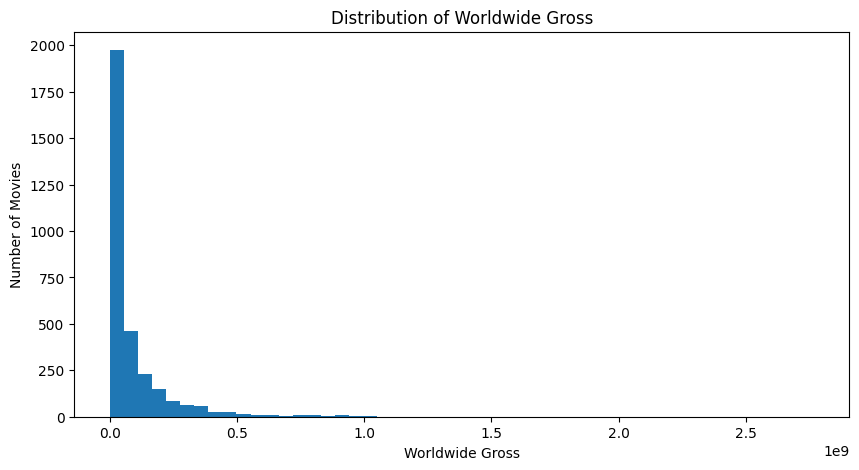

In [123]:
plt.figure(figsize=(10, 5))

plt.hist(
    movies["Worldwide Gross"].dropna(),
    bins=50
)

plt.title("Distribution of Worldwide Gross")
plt.xlabel("Worldwide Gross")
plt.ylabel("Number of Movies")

plt.show()

In [124]:
print("Skewness:", movies["Worldwide Gross"].skew())

print("\nPercentiles:")
print(
    movies["Worldwide Gross"].quantile(
        [0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

Skewness: 4.875484570258709

Percentiles:
0.25    8.765672e+06
0.50    3.222342e+07
0.75    9.878551e+07
0.90    2.312174e+08
0.95    3.578790e+08
0.99    7.837776e+08
Name: Worldwide Gross, dtype: float64


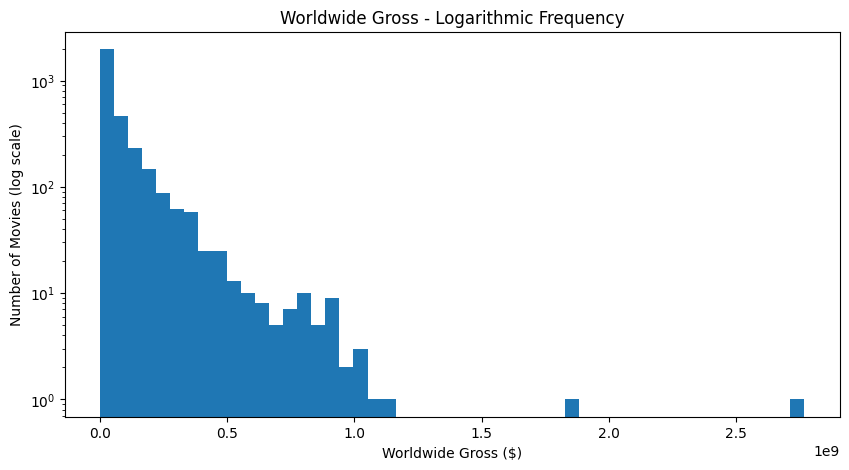

In [125]:
plt.figure(figsize=(10, 5))

plt.hist(
    movies["Worldwide Gross"].dropna(),
    bins=50,
    log=True
)

plt.title("Worldwide Gross - Logarithmic Frequency")
plt.xlabel("Worldwide Gross ($)")
plt.ylabel("Number of Movies (log scale)")

plt.show()

# Controlling duplicate values

In [126]:
print("Exact duplicates:", movies.duplicated().sum())
print("Duplicate titles:", movies["Title"].duplicated().sum())

Exact duplicates: 0
Duplicate titles: 24


# Exploring category columns

In [127]:
categorical_columns = ["MPAA Rating", "Distributor", "Source", "Major Genre", "Creative Type"]

for col in categorical_columns:
    print(f"\n---{col}---")
    print(movies[col].value_counts(dropna=False).head(15))


---MPAA Rating---
MPAA Rating
R            1194
PG-13         865
NaN           605
PG            354
Not Rated      94
G              79
NC-17           8
Open            2
Name: count, dtype: int64

---Distributor---
Distributor
Warner Bros.              318
Sony Pictures             307
Paramount Pictures        257
Universal                 254
NaN                       232
Walt Disney Pictures      232
20th Century Fox          229
MGM                       173
Miramax                   137
New Line                  136
Lionsgate                  88
Sony Pictures Classics     76
Fox Searchlight            63
Dreamworks SKG             53
Focus Features             33
Name: count, dtype: int64

---Source---
Source
Original Screenplay              1536
Based on Book/Short Story         657
NaN                               365
Based on Real Life Events         186
Remake                            126
Based on TV                       106
Based on Comic/Graphic Novel       82
Based

In [128]:
for col in movies.select_dtypes(include="str").columns:
    print(col, (movies[col].str.strip() == "").sum())

Title 0
MPAA Rating 0
Distributor 0
Source 0
Major Genre 0
Creative Type 0
Director 0


# Adding Genre group to data

In [129]:
movies = movies.merge(genre_groups, on="Major Genre", how="left")

In [130]:
print(movies.shape)

print(movies[["Title", "Major Genre", "Genre group"]].head(15))

(3201, 17)
                         Title Major Genre     Genre group
0               The Land Girls         NaN             NaN
1       First Love, Last Rites       Drama           Drama
2   I Married a Strange Person      Comedy  Comedy & music
3         Let's Talk About Sex      Comedy  Comedy & music
4                         Slam       Drama           Drama
5          Mississippi Mermaid         NaN             NaN
6                    Following         NaN             NaN
7                      Foolish      Comedy  Comedy & music
8                      Pirates         NaN             NaN
9              Duel in the Sun         NaN             NaN
10                   Tom Jones         NaN             NaN
11                     Oliver!     Musical  Comedy & music
12       To Kill A Mockingbird         NaN             NaN
13            Tora, Tora, Tora         NaN             NaN
14           Hollywood Shuffle         NaN             NaN


In [131]:
print(genre_groups)

            Major Genre         Genre group
0                 Drama               Drama
1                Comedy      Comedy & music
2       Romantic Comedy      Comedy & music
3          Black Comedy      Comedy & music
4               Musical      Comedy & music
5                Action  Action & adventure
6             Adventure  Action & adventure
7               Western  Action & adventure
8     Thriller/Suspense   Thriller & horror
9                Horror   Thriller & horror
10          Documentary         Non-fiction
11  Concert/Performance         Non-fiction


In [132]:
unmatched = movies[
    movies["Major Genre"].notna() &
    movies["Genre group"].isna()
]

print(unmatched["Major Genre"].value_counts())

Series([], Name: count, dtype: int64)


In [133]:
print(
    movies.nlargest(15, "Release Date")[
        ["Title", "Release Date"]
    ].to_string(index=False)
)

                           Title Release Date
                 Duel in the Sun   2046-12-31
     The Best Years of Our Lives   2046-11-21
                          Wilson   2044-08-01
                 A Guy Named Joe   2043-12-24
                      Cat People   2042-11-16
         How Green Was My Valley   2041-10-28
                        Fantasia   2040-11-13
              Gone with the Wind   2039-12-15
                The Wizard of Oz   2039-08-25
 Snow White and the Seven Dwarfs   2037-12-21
Charge of the Light Brigade, The   2036-10-20
                    Modern Times   2036-02-05
                King Kong (1933)   2033-04-07
                     42nd Street   2033-03-09
              She Done Him Wrong   2033-02-09


In [134]:
future_movies = movies[movies["Release Date"] > "2026-11-26"]

print("Antal filmer med framtida releasedatum:", len(future_movies))

print(
    future_movies["Release Date"]
    .dt.year
    .value_counts()
    .sort_index()
)

Antal filmer med framtida releasedatum: 16
Release Date
2027    1
2033    3
2036    2
2037    1
2039    2
2040    1
2041    1
2042    1
2043    1
2044    1
2046    2
Name: count, dtype: int64


In [135]:
print(
    future_movies[
        ["Title", "Release Date"]
    ].to_string(index=False)
)

                           Title Release Date
                 Duel in the Sun   2046-12-31
                          Wilson   2044-08-01
                     42nd Street   2033-03-09
     The Best Years of Our Lives   2046-11-21
Charge of the Light Brigade, The   2036-10-20
                      Cat People   2042-11-16
                        Fantasia   2040-11-13
                 A Guy Named Joe   2043-12-24
              Gone with the Wind   2039-12-15
         How Green Was My Valley   2041-10-28
                King Kong (1933)   2033-04-07
                    Modern Times   2036-02-05
              She Done Him Wrong   2033-02-09
 Snow White and the Seven Dwarfs   2037-12-21
                           Wings   2027-08-12
                The Wizard of Oz   2039-08-25


In [136]:
mask = movies["Release Date"] > "2026-11-26"

movies.loc[mask, "Release Date"] = pd.NaT

In [137]:
print(movies["Release Date"].isna().sum())

16


In [138]:
missing_rows = movies[
    movies["Title"].isna() |
    movies["Production Budget"].isna()
]

print(missing_rows.to_string())

          Title    US Gross  Worldwide Gross  US DVD Sales  Production Budget Release Date MPAA Rating  Running Time min Distributor               Source        Major Genre         Creative Type Director  Rotten Tomatoes Rating  IMDB Rating  IMDB Votes        Genre group
1271  Baby Mama  60494212.0       64391484.0    24304275.0                NaN   2008-04-25       PG-13              99.0   Universal  Original Screenplay             Comedy  Contemporary Fiction      NaN                    63.0          6.1     16128.0     Comedy & music
3053        NaN     26403.0        3080493.0           NaN          3700000.0   2006-11-03   Not Rated              85.0   IFC Films  Original Screenplay  Thriller/Suspense  Contemporary Fiction      NaN                    39.0          6.6     11986.0  Thriller & horror


In [139]:
string_cols = movies.select_dtypes(include=["str"]).columns

empty_counts = movies[string_cols].apply(
    lambda col: col.str.strip().eq("").sum()
)

print(empty_counts[empty_counts > 0])

Series([], dtype: int64)


# Analyze: Which movies have the highest ratings?

In [140]:
genre_analysis = (
    movies.groupby("Genre group")
    .agg(
        Number_of_movies=("Title", "count"),
        Average_IMDb=("IMDB Rating", "mean"),
        Median_IMDB=("IMDB Rating", "median")
    ).sort_values("Average_IMDb", ascending=False)
)

print(genre_analysis.round(2))

                    Number_of_movies  Average_IMDb  Median_IMDB
Genre group                                                    
Non-fiction                       48          6.93          7.4
Drama                            789          6.77          6.9
Action & adventure               730          6.24          6.4
Thriller & horror                457          6.04          6.1
Comedy & music                   901          5.93          6.0


# Analyze: Which genres have the most revenue?

In [141]:
revenue_analysis = (
    movies.groupby("Genre group")
    .agg(
        Number_of_movies=("Worldwide Gross", "count"),
        Average_revenue=("Worldwide Gross", "mean"),
        Median_revenue=("Worldwide Gross", "median")
    )
    .sort_values("Average_revenue", ascending=False)
)

print((revenue_analysis / [1, 1_000_000, 1_000_000]).round(2))

                    Number_of_movies  Average_revenue  Median_revenue
Genre group                                                          
Action & adventure             725.0           176.30           91.04
Comedy & music                 893.0            75.01           33.42
Thriller & horror              454.0            71.77           35.52
Drama                          783.0            51.69           19.42
Non-fiction                     45.0            18.95            3.22


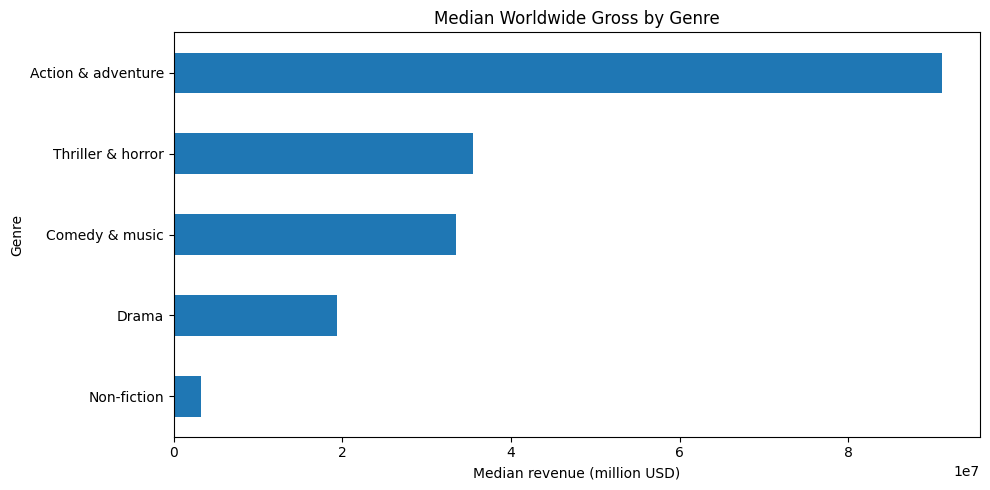

In [142]:
revenue_analysis["Median_revenue"].sort_values().plot(
    kind="barh",
    figsize=(10,5),
    title="Median Worldwide Gross by Genre"
)

plt.xlabel("Median revenue (million USD)")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()

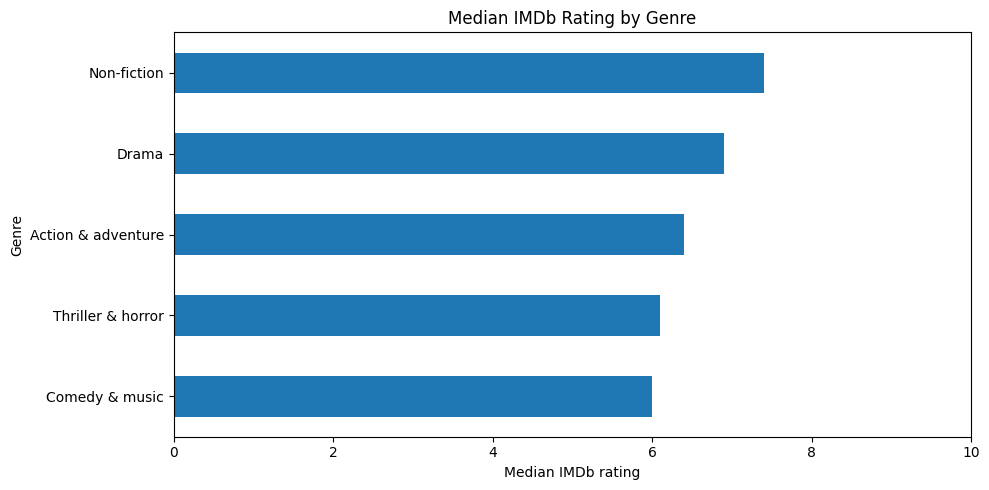

In [146]:
genre_analysis["Median_IMDB"].sort_values().plot(
    kind="barh",
    figsize=(10, 5),
    title="Median IMDb Rating by Genre"
)

plt.xlabel("Median IMDb rating")
plt.ylabel("Genre")
plt.xlim(0, 10)
plt.tight_layout()
plt.show()

Analyze: Connection between budget and revenue

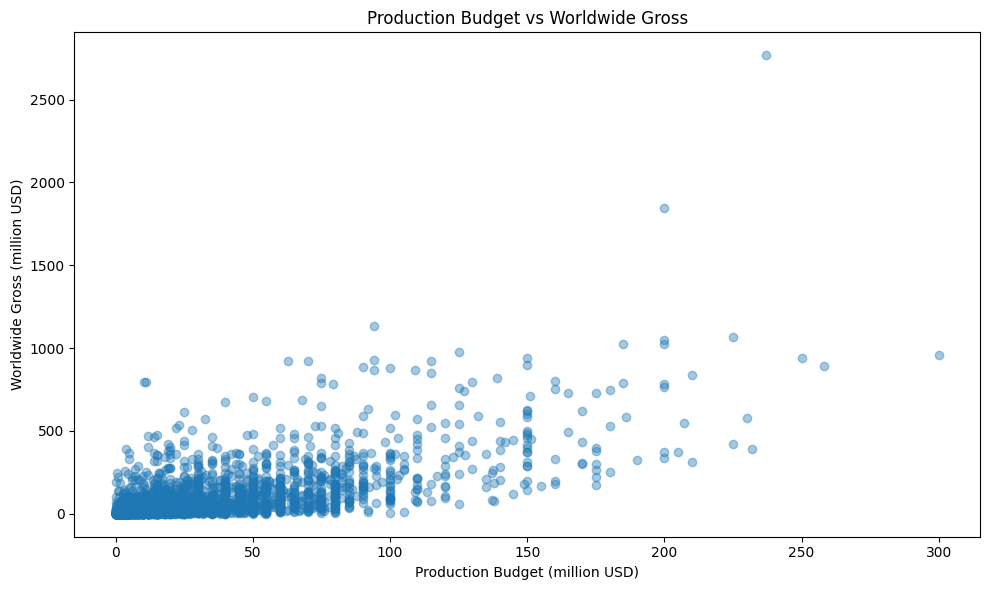

In [148]:
plt.figure(figsize=(10,6))

plt.scatter(
    movies["Production Budget"] / 1_000_000,
    movies["Worldwide Gross"] / 1_000_000,
    alpha = 0.4
)

plt.xlabel("Production Budget (million USD)")
plt.ylabel("Worldwide Gross (million USD)")
plt.title("Production Budget vs Worldwide Gross")

plt.tight_layout()
plt.show()

# Correlation Analysis

In [149]:
correlation = movies[["Production Budget", "Worldwide Gross"]].corr().iloc[0, 1]
print("Correlation:", round(correlation, 3))

Correlation: 0.667


In [150]:
log_data = np.log1p(movies[["Production Budget", "Worldwide Gross"]])
log_correlation = log_data.corr().iloc[0, 1]

print("log correlation:", round(log_correlation, 3))

log correlation: 0.651


# Analyze: Which movies are the most profitable ones?

In [151]:
movies["Revenue Ratio"] = (movies["Worldwide Gross"] / movies["Production Budget"])

In [153]:
top_profitable = movies.nlargest(15, "Revenue Ratio")

print(top_profitable[["Title", "Production Budget", "Worldwide Gross", "Revenue Ratio"]].to_string(index=False))

                      Title  Production Budget  Worldwide Gross  Revenue Ratio
        Paranormal Activity            15000.0      193770453.0   12918.030200
                  Tarnation              218.0        1162014.0    5330.339450
                Deep Throat            25000.0       45000000.0    1800.000000
                    Mad Max           200000.0       99750000.0     498.750000
              Super Size Me            65000.0       29529368.0     454.297969
      The Brothers McMullen            25000.0       10426506.0     417.060240
    The Blair Witch Project           600000.0      248300000.0     413.833333
                El Mariachi             7000.0        2040920.0     291.560000
   Night of the Living Dead           114000.0       30000000.0     263.157895
                      Rocky          1000000.0      225000000.0     225.000000
                  Halloween           325000.0       70000000.0     215.384615
The Texas Chainsaw Massacre           140000.0      

In [154]:
filtered_movies = movies[movies["Production Budget"] >= 100_000].copy()

top_profitable_filtered = filtered_movies.nlargest(15, "Revenue Ratio")

print(top_profitable_filtered[["Title", "Production Budget", "Worldwide Gross", "Revenue Ratio"]].to_string(index=False))

                          Title  Production Budget  Worldwide Gross  Revenue Ratio
                        Mad Max           200000.0       99750000.0     498.750000
        The Blair Witch Project           600000.0      248300000.0     413.833333
       Night of the Living Dead           114000.0       30000000.0     263.157895
                          Rocky          1000000.0      225000000.0     225.000000
                      Halloween           325000.0       70000000.0     215.384615
    The Texas Chainsaw Massacre           140000.0       26572439.0     189.803136
              American Graffiti           777000.0      140000000.0     180.180180
                           Once           150000.0       18997174.0     126.647827
               The Stewardesses           200000.0       25000000.0     125.000000
Snow White and the Seven Dwarfs          1488000.0      184925485.0     124.277880
  The Rocky Horror Picture Show          1200000.0      139876417.0     116.563681
    

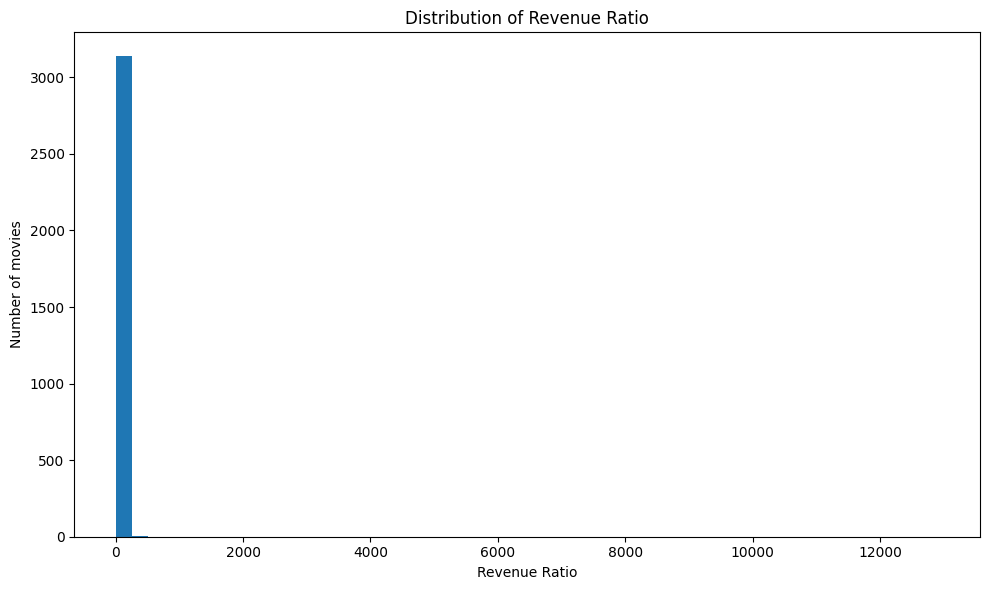

In [155]:
plt.figure(figsize=(10,6))

plt.hist(movies["Revenue Ratio"].dropna(), bins = 50)

plt.xlabel("Revenue Ratio")
plt.ylabel("Number of movies")
plt.title("Distribution of Revenue Ratio")

plt.tight_layout()
plt.show()

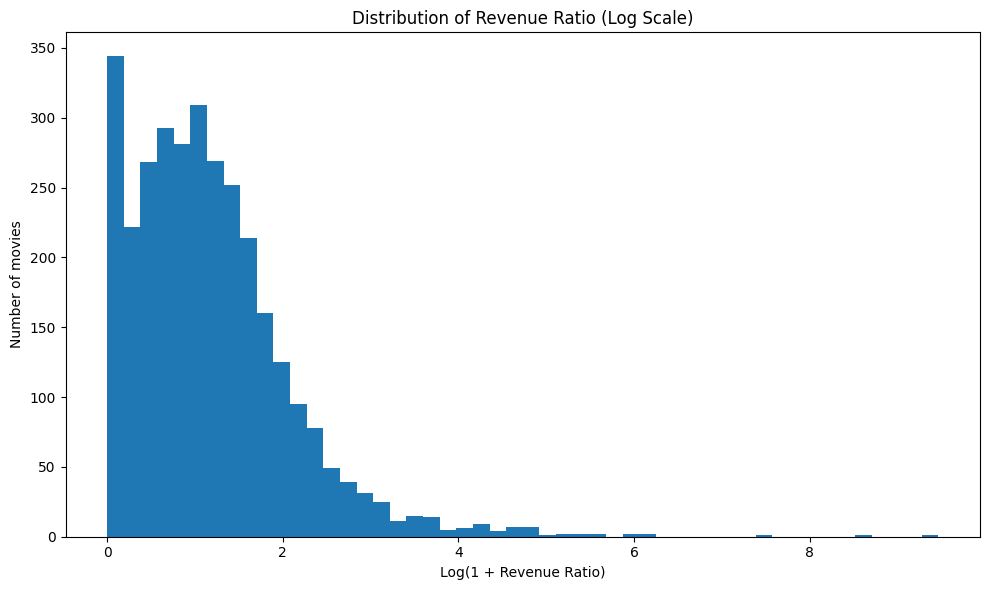

In [156]:
plt.figure(figsize=(10, 6))

plt.hist(
    np.log1p(movies["Revenue Ratio"].dropna()),
    bins=50
)

plt.xlabel("Log(1 + Revenue Ratio)")
plt.ylabel("Number of movies")
plt.title("Distribution of Revenue Ratio (Log Scale)")

plt.tight_layout()
plt.show()